In [1]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import set_config
set_config(transform_output='pandas')

In [4]:
data=load_breast_cancer()
x=data.data
y=data.target

In [7]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)

In [10]:
model=RandomForestClassifier(n_estimators=100,
                             criterion='gini',
                             bootstrap=True,
                             oob_score=True,
                             random_state=42)

model.fit(x_train,y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the followi

In [13]:
print(model.feature_importances_)
print(model.oob_score_)

[0.06867599 0.00958431 0.06957388 0.04917215 0.00559816 0.01171465
 0.05763806 0.09088475 0.00466601 0.00448887 0.01677021 0.00521386
 0.0096331  0.03310446 0.00349852 0.00597922 0.00431035 0.00409824
 0.00401198 0.00444169 0.09769574 0.01859665 0.07222637 0.14001599
 0.0124362  0.01860002 0.03434013 0.12952961 0.00833452 0.00516632]
0.9538461538461539


In [14]:
y_pred=model.predict(x_test)

In [42]:
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix,ConfusionMatrixDisplay
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

[[39  3]
 [ 2 70]]


In [43]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

In [20]:
ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test,y_pred))

In [44]:
score_text = (
    f"Accuracy  : {accuracy:.3f}\n"
    f"Precision : {precision:.3f}\n"
    f"Recall    : {recall:.3f}\n"
    f"F1-Score  : {f1:.3f}"
)

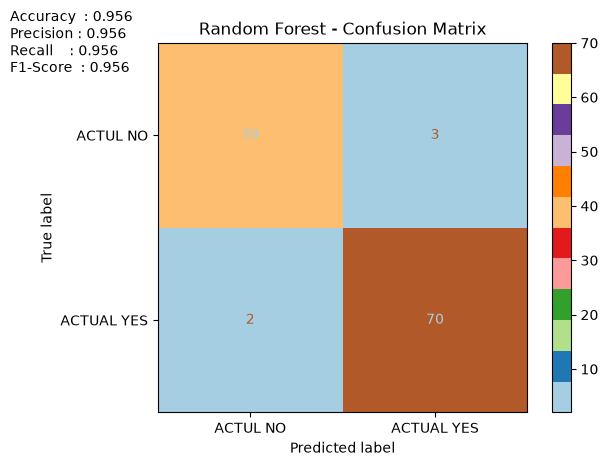

In [53]:
import matplotlib.pyplot as plt
display=ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test,y_pred), display_labels=['ACTUL NO', 'ACTUAL YES'])
display.plot(cmap='Paired')
plt.title("Random Forest - Confusion Matrix")
plt.text(x=-1.3,y=-0.5,s=score_text,verticalalignment='center')
plt.show()

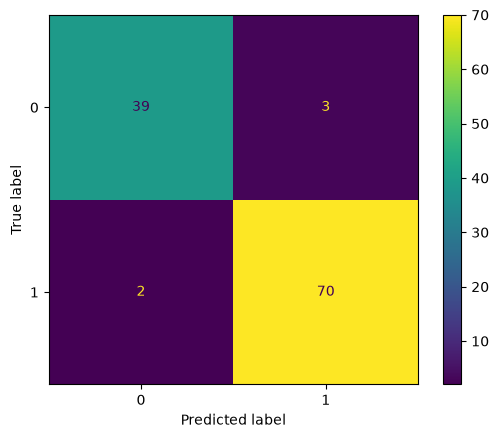

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,cmap='viridis')

In [32]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


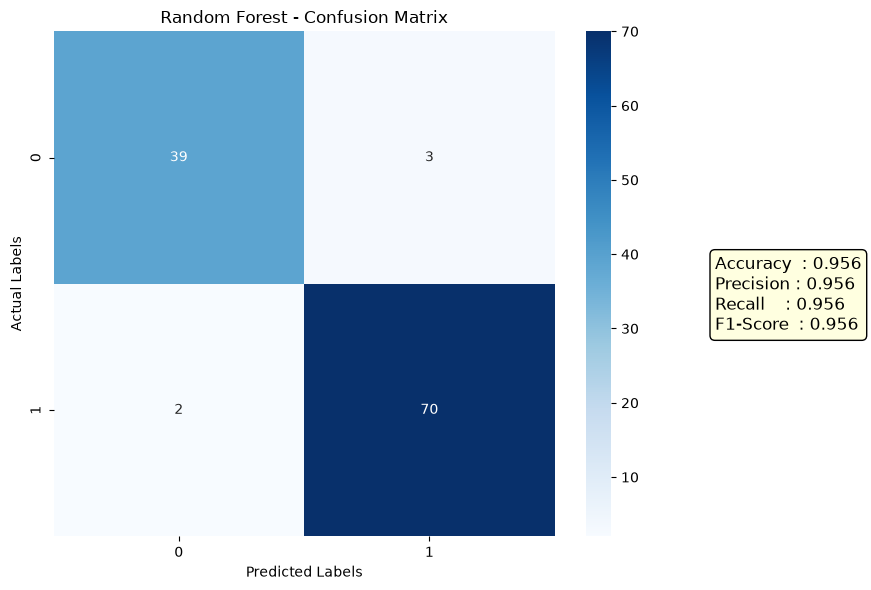

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate scores
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=ax
)

ax.set_title("Random Forest - Confusion Matrix")
ax.set_xlabel("Predicted Labels")
ax.set_ylabel("Actual Labels")

# Display scores on chart
score_text = (
    f"Accuracy  : {accuracy:.3f}\n"
    f"Precision : {precision:.3f}\n"
    f"Recall    : {recall:.3f}\n"
    f"F1-Score  : {f1:.3f}"
)

fig.text(
    0.72, 0.50,
    score_text,
    fontsize=12,
    verticalalignment='center',
    bbox=dict(boxstyle='round', facecolor='lightyellow')
)

plt.tight_layout(rect=[0, 0, 0.70, 1])
plt.show()